# Mine hard-positive segments — 22 October 2026
Inputs are the new strict left/right double-tap originals in `hard_positive_mining_22_10_26/source_recordings/`, auto-labeled with **1950–2750 ms**. No easy/new original is automatically added to the dataset.

A segment is **hard** if at least one selected model's maximum **correct-side** probability in the inclusive **−500 to +500 ms around its label** is below that model's side threshold. The scoring window is clipped to its own segment. A high wrong-side peak does not rescue it; equality with the threshold counts as easy. This is a confidence diagnostic, not event recall after alarm/cooldown matching.

By default both preprocessing and model state reset for each segment, matching standalone segment crops. Only hard segments with one valid label can be exported. Unlabeled/ambiguous segments are audited, never exported as negatives. Exports preserve the whole segment and remap the positive label. Nothing is exported by default.

In [4]:
from pathlib import Path
import importlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis import hard_negative_mining as negative, hard_positive_mining as mining
importlib.reload(mining)
torch.set_num_threads(2)
MINING_WORKSPACE = ROOT / 'hard_positive_mining_22_10_26'
INPUT_DIR = MINING_WORKSPACE / 'source_recordings'
OUTPUT_DIR = MINING_WORKSPACE / 'crops'
MODELS = {
    'best (1510d8(62))': {
            'checkpoint': ROOT / 'testing_checkpoints/1510d8(62)/best.pt',
            'left_threshold': 0.8, 'right_threshold': 0.8,
        },
        '(1510d8(52))': {
            'checkpoint': ROOT / 'testing_checkpoints/1510d8(52)/best.pt',
            'left_threshold': 0.8, 'right_threshold': 0.8,
        },
        '(1510d8(102))': {
            'checkpoint': ROOT / 'testing_checkpoints/1510d8(102)/best.pt',
            'left_threshold': 0.8, 'right_threshold': 0.8,
        },
}
RESET_AT_SEGMENTS = True  # Reset preprocessing AND model state per segment.
FULL_INFERENCE_CHUNK_FRAMES = 4096


## 1. Inventory and strict-label audit
Source labels and `.labeling.json` metadata are already prepared. The report records 20 events per source and zero missed segments. Define models in setup, then rerun this cell before mining.

In [5]:
inventory = negative.recording_inventory(INPUT_DIR)
display(inventory)
labeling_report = pd.read_csv(MINING_WORKSPACE / 'labeling_report.csv')
display(labeling_report)
models = {name: negative.load_mining_model(spec['checkpoint']) for name, spec in MODELS.items()}
print('Models:', ', '.join(models) or 'none configured yet')


,file,user,action,frames,recording_type,seconds,sample_rate_hz,sessions,annotated_events
0,imuStrict_MiguelL_knock_twice_left_20261016_19...,MiguelL,knock_twice_left,6050,knock_twice,60.50,100.0,20,20
1,imuStrict_MiguelL_knock_twice_left_20261016_19...,MiguelL,knock_twice_left,6056,knock_twice,60.56,100.0,20,20
2,imuStrict_MiguelL_knock_twice_left_20261018_16...,MiguelL,knock_twice_left,6049,knock_twice,60.49,100.0,20,20
3,imuStrict_MiguelL_knock_twice_left_20261019_19...,MiguelL,knock_twice_left,6051,knock_twice,60.51,100.0,20,20
4,imuStrict_MiguelL_knock_twice_left_20261019_20...,MiguelL,knock_twice_left,6046,knock_twice,60.46,100.0,20,20
5,imuStrict_MiguelL_knock_twice_left_20261019_20...,MiguelL,knock_twice_left,6055,knock_twice,60.55,100.0,20,20
6,imuStrict_MiguelL_knock_twice_left_20261022_17...,MiguelL,knock_twice_left,6044,knock_twice,60.44,100.0,20,20
7,imuStrict_MiguelL_knock_twice_left_20261022_17...,MiguelL,knock_twice_left,6053,knock_twice,60.53,100.0,20,20
8,imuStrict_MiguelL_knock_twice_left_20261022_18...,MiguelL,knock_twice_left,6056,knock_twice,60.56,100.0,20,20
9,imuStrict_MiguelL_knock_twice_left_20261022_18...,MiguelL,knock_twice_left,6038,knock_twice,60.38,100.0,20,20


,file,source_sha256,source_labels_sha256,segments,events,misses,strict_start_ms,strict_end_ms
0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,20,20,0,1950,2750
1,imuStrict_MiguelL_knock_twice_left_20261016_19...,c0e660aaa1f8ec8306e4b69ee8694e82c26b8e80b81a26...,c1457bc374e8eef7262cab432fa9f1cc79bcab51dd0b36...,20,20,0,1950,2750
2,imuStrict_MiguelL_knock_twice_left_20261018_16...,df04c31a0a82922abc20b12bd2ffb6e2454eb24df35ad0...,3d8fd4a893a85e9d6f2eb30712a332e4d3d34cf123b742...,20,20,0,1950,2750
3,imuStrict_MiguelL_knock_twice_left_20261019_19...,5bc7e1058ab4c41a8da7021d55545df1205a6e6e11f1ae...,df1d7cb81e2bf60b5140d2cbafd423e025f458921b7930...,20,20,0,1950,2750
4,imuStrict_MiguelL_knock_twice_left_20261019_20...,bca491af787c30e5b76844ce28fcf7dd72cba58c8c4a67...,a08a39a60460ead070443c638504c4fc284c4b563f40df...,20,20,0,1950,2750
5,imuStrict_MiguelL_knock_twice_left_20261019_20...,68a0f99e895a253714769a6876813cf4204da370606e1b...,002e54fa3e02402ec1ee355166b090e6ba035cf5325339...,20,20,0,1950,2750
6,imuStrict_MiguelL_knock_twice_left_20261022_17...,6a94c3917ffafa35cd43272c17c2cf36e6dc770fe16638...,625d5e5e0697bb30dc0e66e07d052c2651f3d0b17851bd...,20,20,0,1950,2750
7,imuStrict_MiguelL_knock_twice_left_20261022_17...,edcaf312cfee69069043d735bedad2be1fe1a623df6d3f...,2059218191f83f2ec035fdc30c5dea20a3544dc6cc04cf...,20,20,0,1950,2750
8,imuStrict_MiguelL_knock_twice_left_20261022_18...,ecd0bd5931d59ac98246d5cc9677104ece5e2d14a0abf8...,2406211285c5a93292c1b0113656cf02f23702d97769fc...,20,20,0,1950,2750
9,imuStrict_MiguelL_knock_twice_left_20261022_18...,d073283c29e60195ddd28356a653ae36a45092696e395b...,2fe32d6c9dd891897dea7b9f4c8900188416a46257ff8a...,20,20,0,1950,2750


Models: best (1510d8(62)), (1510d8(52)), (1510d8(102))


## 2. Score every segment; retain the any-model hard union
Choose left/right sources with `BATCH_SIDES`, explicit filenames with `BATCH_FILES`, and per-model thresholds in setup. Tables include all easy/unlabeled segments for audit, while `hard_candidates` is exactly the union used for export. Global candidate IDs identify segments, not individual model failures. All-easy sources remain in file statistics.

Keep `SAVE_ALL_HARD_POSITIVES=False` until ready. Setting it to `True` writes every selected hard segment; easy segments are never exported. Raw values stay unchanged and positive labels remain positive.

In [8]:
BATCH_FILES = []
BATCH_SELECT_ALL = True
BATCH_SIDES = ['left', 'right']
BATCH_MODELS = list(MODELS)
SCORE_BEFORE_MS = 500.0
SCORE_AFTER_MS = 500.0
TRAINING_WINDOW_FRAMES = 300
SAVE_ALL_HARD_POSITIVES = True
assert BATCH_MODELS and set(BATCH_MODELS) <= set(models), 'Define MODELS and rerun setup + inventory first.'
assert BATCH_SIDES and set(BATCH_SIDES) <= {'left', 'right'}
eligible = inventory[(inventory.recording_type == 'knock_twice') &
                     inventory.action.isin(['knock_twice_' + side for side in BATCH_SIDES]) &
                     ~inventory.file.str.contains('__crop_', regex=False)]
batch_files = eligible.file.tolist() if BATCH_SELECT_ALL else list(BATCH_FILES)
assert batch_files and len(batch_files) == len(set(batch_files)) and set(batch_files) <= set(eligible.file)
batch_thresholds = {name: (MODELS[name]['left_threshold'], MODELS[name]['right_threshold']) for name in BATCH_MODELS}
hard_candidates, all_segments, model_scores, batch_file_stats = mining.mine_recordings(
    [INPUT_DIR / file for file in batch_files], {name: models[name] for name in BATCH_MODELS},
    batch_thresholds, score_before_ms=SCORE_BEFORE_MS, score_after_ms=SCORE_AFTER_MS,
    reset_at_segments=RESET_AT_SEGMENTS, training_window_frames=TRAINING_WINDOW_FRAMES,
    chunk_frames=FULL_INFERENCE_CHUNK_FRAMES, progress=print)
positive_trace_cache = {}  # Review-only cache; rebuilt whenever the batch is rescored.
display(batch_file_stats)
display(hard_candidates)
display(model_scores)
print(f'{len(hard_candidates)} hard segments / {len(all_segments)} total segments')
batch_exports = (mining.export_batch(hard_candidates, INPUT_DIR, OUTPUT_DIR)
                 if SAVE_ALL_HARD_POSITIVES else pd.DataFrame())
if SAVE_ALL_HARD_POSITIVES:
    display(batch_exports)


[1/24] imuStrict_MiguelL_knock_twice_left_20261016_190650.csv
[2/24] imuStrict_MiguelL_knock_twice_left_20261016_190922.csv
[3/24] imuStrict_MiguelL_knock_twice_left_20261018_160138.csv
[4/24] imuStrict_MiguelL_knock_twice_left_20261019_190433.csv
[5/24] imuStrict_MiguelL_knock_twice_left_20261019_204237.csv
[6/24] imuStrict_MiguelL_knock_twice_left_20261019_204401.csv
[7/24] imuStrict_MiguelL_knock_twice_left_20261022_175714.csv
[8/24] imuStrict_MiguelL_knock_twice_left_20261022_175943.csv
[9/24] imuStrict_MiguelL_knock_twice_left_20261022_181106.csv
[10/24] imuStrict_MiguelL_knock_twice_left_20261022_185051.csv
[11/24] imuStrict_MiguelL_knock_twice_left_20261023_090724.csv
[12/24] imuStrict_MiguelL_knock_twice_left_20261023_090931.csv
[13/24] imuStrict_MiguelL_knock_twice_left_20261023_091643.csv
[14/24] imuStrict_MiguelL_knock_twice_right_20261016_185945.csv
[15/24] imuStrict_MiguelL_knock_twice_right_20261016_190147.csv
[16/24] imuStrict_MiguelL_knock_twice_right_20261016_191044.cs

,file,source_sha256,segments,labeled_segments,hard_segments,easy_segments,unlabeled_segments,ambiguous_segments,recording_seconds,hard_segment_seconds
0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,20,20,12,8,0,0,60.50,36.27
1,imuStrict_MiguelL_knock_twice_left_20261016_19...,c0e660aaa1f8ec8306e4b69ee8694e82c26b8e80b81a26...,20,20,15,5,0,0,60.56,45.41
2,imuStrict_MiguelL_knock_twice_left_20261018_16...,df04c31a0a82922abc20b12bd2ffb6e2454eb24df35ad0...,20,20,14,6,0,0,60.49,42.38
3,imuStrict_MiguelL_knock_twice_left_20261019_19...,5bc7e1058ab4c41a8da7021d55545df1205a6e6e11f1ae...,20,20,14,6,0,0,60.51,42.37
4,imuStrict_MiguelL_knock_twice_left_20261019_20...,bca491af787c30e5b76844ce28fcf7dd72cba58c8c4a67...,20,20,15,5,0,0,60.46,45.33
5,imuStrict_MiguelL_knock_twice_left_20261019_20...,68a0f99e895a253714769a6876813cf4204da370606e1b...,20,20,14,6,0,0,60.55,42.39
6,imuStrict_MiguelL_knock_twice_left_20261022_17...,6a94c3917ffafa35cd43272c17c2cf36e6dc770fe16638...,20,20,9,11,0,0,60.44,27.23
7,imuStrict_MiguelL_knock_twice_left_20261022_17...,edcaf312cfee69069043d735bedad2be1fe1a623df6d3f...,20,20,4,16,0,0,60.53,12.06
8,imuStrict_MiguelL_knock_twice_left_20261022_18...,ecd0bd5931d59ac98246d5cc9677104ece5e2d14a0abf8...,20,20,9,11,0,0,60.56,27.32
9,imuStrict_MiguelL_knock_twice_left_20261022_18...,d073283c29e60195ddd28356a653ae36a45092696e395b...,20,20,18,2,0,0,60.38,54.33


,candidate_id,file,source_sha256,source_labels_sha256,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,class_id,...,window_clipped,status,is_hard,model,trigger_models,score_details,reset_at_segments,training_window_frames,training_retains_event,mining_models
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,1,0,301,301,3.01,1,...,False,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
1,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,2,301,601,300,3.00,1,...,False,labeled,True,(1510d8(102)),[(1510d8(102))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
2,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,3,601,903,302,3.02,1,...,False,labeled,True,(1510d8(102)),[(1510d8(102))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
3,3,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,4,903,1207,304,3.04,1,...,False,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
4,4,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,5,1207,1508,301,3.01,1,...,False,labeled,True,best (1510d8(62)),[best (1510d8(62))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,475,imuStrict_MiguelL_knock_twice_right_20261023_0...,9e7a2cfbdf152afbfe052e163aabd7e0bb7d3daea5007e...,9d5c6d22eb51c3f82c40ebe37c18dd08fe06e0a7c55252...,16,4534,4834,300,3.00,2,...,True,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
476,476,imuStrict_MiguelL_knock_twice_right_20261023_0...,9e7a2cfbdf152afbfe052e163aabd7e0bb7d3daea5007e...,9d5c6d22eb51c3f82c40ebe37c18dd08fe06e0a7c55252...,17,4834,5137,303,3.03,2,...,False,labeled,True,(1510d8(52)),"[(1510d8(52)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
477,477,imuStrict_MiguelL_knock_twice_right_20261023_0...,9e7a2cfbdf152afbfe052e163aabd7e0bb7d3daea5007e...,9d5c6d22eb51c3f82c40ebe37c18dd08fe06e0a7c55252...,18,5137,5439,302,3.02,2,...,False,labeled,True,(1510d8(52)),"[(1510d8(102)), (1510d8(52)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
478,478,imuStrict_MiguelL_knock_twice_right_20261023_0...,9e7a2cfbdf152afbfe052e163aabd7e0bb7d3daea5007e...,9d5c6d22eb51c3f82c40ebe37c18dd08fe06e0a7c55252...,19,5439,5739,300,3.00,2,...,False,labeled,True,(1510d8(102)),"[(1510d8(102)), (1510d8(52)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."


,candidate_id,file,segment_index,model,class_id,threshold,peak_probability,peak_frame,is_hard
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,best (1510d8(62)),1,0.8,0.883830,247,False
1,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(52)),1,0.8,0.797930,244,True
2,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(102)),1,0.8,0.887213,245,False
3,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,2,best (1510d8(62)),1,0.8,0.813624,549,False
4,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,2,(1510d8(52)),1,0.8,0.882779,545,False
...,...,...,...,...,...,...,...,...,...
1435,478,imuStrict_MiguelL_knock_twice_right_20261023_0...,19,(1510d8(52)),2,0.8,0.764532,5697,True
1436,478,imuStrict_MiguelL_knock_twice_right_20261023_0...,19,(1510d8(102)),2,0.8,0.737401,5689,True
1437,479,imuStrict_MiguelL_knock_twice_right_20261023_0...,20,best (1510d8(62)),2,0.8,0.214975,5993,True
1438,479,imuStrict_MiguelL_knock_twice_right_20261023_0...,20,(1510d8(52)),2,0.8,0.002807,5990,True


294 hard segments / 480 total segments


,candidate_id,file,csv,label,provenance,frames,seconds,label_in_crop,class_id,status
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,301,3.01,238,1,exported
1,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.00,238,1,exported
2,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,302,3.02,249,1,exported
3,3,imuStrict_MiguelL_knock_twice_left_20261016_19...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,304,3.04,250,1,exported
4,4,imuStrict_MiguelL_knock_twice_left_20261016_19...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,301,3.01,238,1,exported
...,...,...,...,...,...,...,...,...,...,...
289,475,imuStrict_MiguelL_knock_twice_right_20261023_0...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.00,253,2,exported
290,476,imuStrict_MiguelL_knock_twice_right_20261023_0...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,303,3.03,250,2,exported
291,477,imuStrict_MiguelL_knock_twice_right_20261023_0...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,302,3.02,249,2,exported
292,478,imuStrict_MiguelL_knock_twice_right_20261023_0...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.00,244,2,exported


## 3. Review one source: hard segments and all-model scores
The table uses the exact batch selection; the overview plots each model's correct-side peak for every labeled segment. Easy segments remain visible for comparison. This cell does not export.

,file,source_sha256,segments,labeled_segments,hard_segments,easy_segments,unlabeled_segments,ambiguous_segments,recording_seconds,hard_segment_seconds
0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,20,20,12,8,0,0,60.5,36.27


,candidate_id,file,source_sha256,source_labels_sha256,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,class_id,...,window_clipped,status,is_hard,model,trigger_models,score_details,reset_at_segments,training_window_frames,training_retains_event,mining_models
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,1,0,301,301,3.01,1,...,False,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
1,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,2,301,601,300,3.00,1,...,False,labeled,True,(1510d8(102)),[(1510d8(102))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
2,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,3,601,903,302,3.02,1,...,False,labeled,True,(1510d8(102)),[(1510d8(102))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
3,3,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,4,903,1207,304,3.04,1,...,False,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
4,4,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,5,1207,1508,301,3.01,1,...,False,labeled,True,best (1510d8(62)),[best (1510d8(62))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
6,6,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,7,1808,2113,305,3.05,1,...,True,labeled,True,(1510d8(102)),"[(1510d8(102)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
7,7,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,8,2113,2414,301,3.01,1,...,False,labeled,True,best (1510d8(62)),[best (1510d8(62))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
8,8,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,9,2414,2718,304,3.04,1,...,False,labeled,True,(1510d8(52)),"[(1510d8(52)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
9,9,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,10,2718,3022,304,3.04,1,...,False,labeled,True,(1510d8(102)),[(1510d8(102))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
13,13,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,14,3935,4239,304,3.04,1,...,False,labeled,True,(1510d8(102)),"[(1510d8(102)), (1510d8(52)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."


,candidate_id,file,segment_index,model,class_id,threshold,peak_probability,peak_frame,is_hard
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,best (1510d8(62)),1,0.8,0.883830,247,False
1,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(52)),1,0.8,0.797930,244,True
2,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(102)),1,0.8,0.887213,245,False
3,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,2,best (1510d8(62)),1,0.8,0.813624,549,False
4,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,2,(1510d8(52)),1,0.8,0.882779,545,False
5,1,imuStrict_MiguelL_knock_twice_left_20261016_19...,2,(1510d8(102)),1,0.8,0.005449,561,True
6,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,3,best (1510d8(62)),1,0.8,0.905520,841,False
7,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,3,(1510d8(52)),1,0.8,0.930152,841,False
8,2,imuStrict_MiguelL_knock_twice_left_20261016_19...,3,(1510d8(102)),1,0.8,0.710996,841,True
9,3,imuStrict_MiguelL_knock_twice_left_20261016_19...,4,best (1510d8(62)),1,0.8,0.940074,1152,False


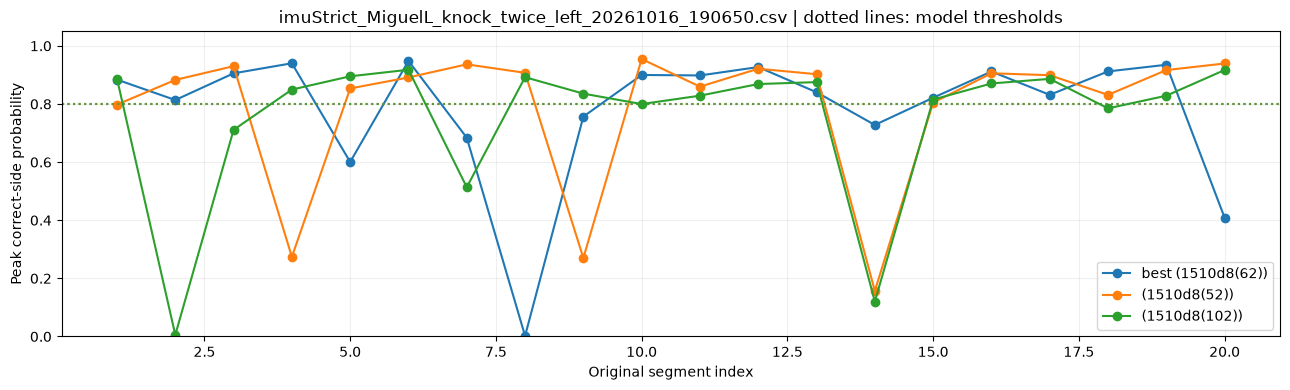

In [9]:
REVIEW_FILE = next(iter(batch_files), None)
REVIEW_HARD_ONLY = True
assert REVIEW_FILE in batch_files
source_segments = all_segments[all_segments.file == REVIEW_FILE]
display(batch_file_stats[batch_file_stats.file == REVIEW_FILE])
display(source_segments[source_segments.is_hard] if REVIEW_HARD_ONLY else source_segments)
source_scores = model_scores[model_scores.file == REVIEW_FILE]
display(source_scores)
fig, axis = plt.subplots(figsize=(13, 4))
for name, scores in source_scores.groupby('model', sort=False):
    line, = axis.plot(scores.segment_index, scores.peak_probability, 'o-', label=name)
    axis.axhline(scores.threshold.iloc[0], color=line.get_color(), ls=':', alpha=.7)
axis.set(xlabel='Original segment index', ylabel='Peak correct-side probability', ylim=(0, 1.05),
         title=REVIEW_FILE + ' | dotted lines: model thresholds')
if not source_scores.empty:
    axis.legend()
axis.grid(alpha=.2)
plt.tight_layout()
plt.show()


## 4. Detailed inspection of one hard positive segment
Set `DETAIL_CANDIDATE_ID` from the tables above. This separate cell shows raw acceleration/gyro, every model's left/right traces, the label, the ±500 ms scoring interval and each correct-side peak/threshold. You can also enter an easy segment's ID from `all_segments`. It uses the batch's inference-reset mode and model set.

,candidate_id,file,source_sha256,source_labels_sha256,segment_index,crop_start_frame,crop_end_frame,crop_frames,crop_seconds,class_id,...,window_clipped,status,is_hard,model,trigger_models,score_details,reset_at_segments,training_window_frames,training_retains_event,mining_models
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,0b239bbd06b1730fa33583229705c2835b1ac07ac75c4d...,d0b97dc77d75abacb13ee46514108be12b80dc71634f3c...,1,0,301,301,3.01,1,...,False,labeled,True,(1510d8(52)),[(1510d8(52))],"[{'model': 'best (1510d8(62))', 'threshold': 0...",True,300,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."


,candidate_id,file,segment_index,model,class_id,threshold,peak_probability,peak_frame,is_hard
0,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,best (1510d8(62)),1,0.8,0.883830,247,False
1,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(52)),1,0.8,0.797930,244,True
2,0,imuStrict_MiguelL_knock_twice_left_20261016_19...,1,(1510d8(102)),1,0.8,0.887213,245,False


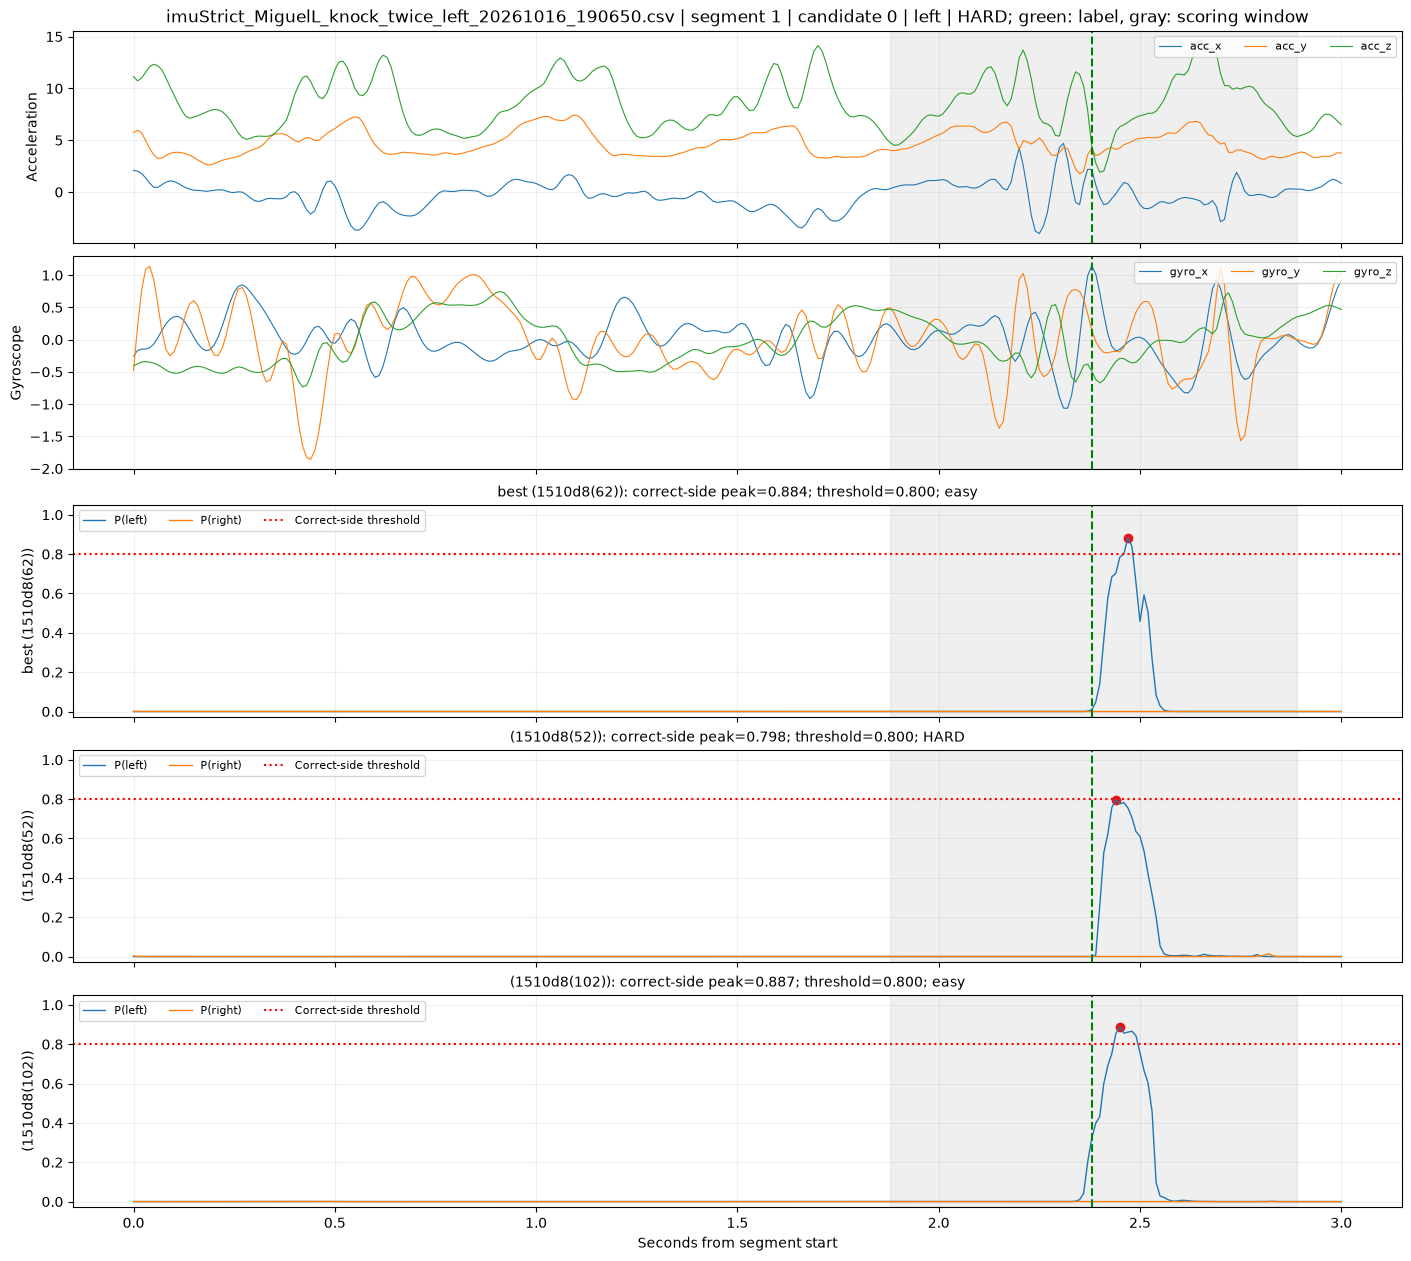

In [10]:
DETAIL_CANDIDATE_ID = next(iter(hard_candidates.candidate_id), None)
if DETAIL_CANDIDATE_ID is None:
    print('No hard positives; choose an ID from all_segments to inspect an easy/unlabeled segment.')
else:
    assert DETAIL_CANDIDATE_ID in set(all_segments.candidate_id)
    detail = all_segments[all_segments.candidate_id == DETAIL_CANDIDATE_ID].iloc[0]
    detail_recording = negative.load_recording(INPUT_DIR / detail.file)
    cache_key = (detail.file, detail.source_sha256, detail.source_labels_sha256)
    if cache_key not in positive_trace_cache:
        positive_trace_cache[cache_key] = {
            name: mining.predict_positive_recording(detail_recording, models[name],
                                                     bool(detail.reset_at_segments), FULL_INFERENCE_CHUNK_FRAMES)
            for name in BATCH_MODELS}
    display(pd.DataFrame([detail]))
    display(model_scores[model_scores.candidate_id == DETAIL_CANDIDATE_ID])
    mining.plot_segment(detail_recording, positive_trace_cache[cache_key], batch_thresholds, detail)
    plt.show()


## 5. Export explicitly chosen hard positives
Optional alternative to exporting every hard segment. Each export is a raw whole-segment CSV, a nonempty `.txt` with its remapped positive event and `.mining.json` provenance including all model scores, the raw/label hashes and strict-label configuration. Identical reruns reuse outputs; conflicting outputs are never overwritten. Add crops to dataset splits only after deciding the allocation; do not also add their full source recordings.

In [ ]:
POSITIVE_KEEP_IDS = []
SAVE_SELECTED_HARD_POSITIVES = False
assert len(POSITIVE_KEEP_IDS) == len(set(POSITIVE_KEEP_IDS))
assert set(POSITIVE_KEEP_IDS) <= set(hard_candidates.candidate_id), 'Only hard labeled segments may be exported.'
selected_positives = hard_candidates[hard_candidates.candidate_id.isin(POSITIVE_KEEP_IDS)]
positive_exports = (mining.export_batch(selected_positives, INPUT_DIR, OUTPUT_DIR)
                    if SAVE_SELECTED_HARD_POSITIVES else pd.DataFrame())
display(positive_exports)
